# 06 — Classification Threshold Analysis

## Objective

This notebook analyzes how the classification threshold affects customer churn predictions.

The selected tuned Gradient Boosting model is kept fixed. Different probability thresholds are evaluated using out-of-fold predictions generated exclusively from the training data.

The goal is to quantify the trade-off between precision, recall, false positives and false negatives, and to select a defensible threshold before final evaluation on the held-out test set.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

In [2]:
PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_FnUseC_TelcoCustomerChurn.csv"
)

df = pd.read_csv(DATA_PATH)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df.shape

(7043, 21)

In [3]:
X = df.drop(
    columns=[
        "customerID",
        "Churn"
    ]
)

y = df["Churn"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [5]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

In [6]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [7]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

In [9]:
selected_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=0.1,
                max_depth=1,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ]
)

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Out-of-Fold Probability Estimation

Threshold selection should not be performed using predictions generated from observations that the model has already seen during fitting.

Therefore, out-of-fold probabilities are generated with stratified cross-validation.

Each training customer receives a churn probability from a model that was trained without that customer's validation fold.

In [11]:
oof_probabilities = cross_val_predict(
    selected_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [12]:
oof_probabilities.shape

(5634,)

In [13]:
oof_probabilities[:10]

array([0.30377678, 0.24249955, 0.02915753, 0.06900358, 0.57896997,
       0.02826204, 0.33470207, 0.1447633 , 0.03686487, 0.05731663])

In [14]:
oof_roc_auc = roc_auc_score(
    y_train,
    oof_probabilities
)

oof_roc_auc

0.850379415640926

## Threshold Evaluation

The default classification threshold of 0.50 is not necessarily optimal for the business objective.

Lower thresholds generally increase recall by identifying more potential churners, but may also increase false positives and reduce precision.

Higher thresholds generally produce fewer churn alerts, potentially increasing precision but reducing recall.

A range of thresholds is therefore evaluated using the out-of-fold training probabilities.

In [15]:
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

thresholds

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ,
       0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ])

In [16]:
threshold_results = []

for threshold in thresholds:

    predictions = np.where(
        oof_probabilities >= threshold,
        "Yes",
        "No"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=["No", "Yes"]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,

        "accuracy": accuracy_score(
            y_train,
            predictions
        ),

        "precision": precision_score(
            y_train,
            predictions,
            pos_label="Yes",
            zero_division=0
        ),

        "recall": recall_score(
            y_train,
            predictions,
            pos_label="Yes",
            zero_division=0
        ),

        "f1": f1_score(
            y_train,
            predictions,
            pos_label="Yes",
            zero_division=0
        ),

        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "true_negatives": tn
    })

In [17]:
threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,threshold,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
0,0.10,0.6150,0.4037,0.9452,0.5658,2087,82,1413,2052
1,0.15,0.6713,0.4417,0.9043,0.5935,1709,143,1352,2430
2,0.20,0.7160,0.4806,0.8689,0.6189,1404,196,1299,2735
3,0.25,0.7444,0.5113,0.8288,0.6325,1184,256,1239,2955
4,0.30,0.7629,0.5368,0.7753,0.6344,1000,336,1159,3139
5,0.35,0.7859,0.5775,0.7204,0.6411,788,418,1077,3351
6,0.40,0.7973,0.6100,0.6548,0.6316,626,516,979,3513
7,0.45,0.8056,0.6435,0.6000,0.6210,497,598,897,3642
8,0.50,0.8053,0.6669,0.5318,0.5917,397,700,795,3742
9,0.55,0.8035,0.7012,0.4522,0.5498,288,819,676,3851


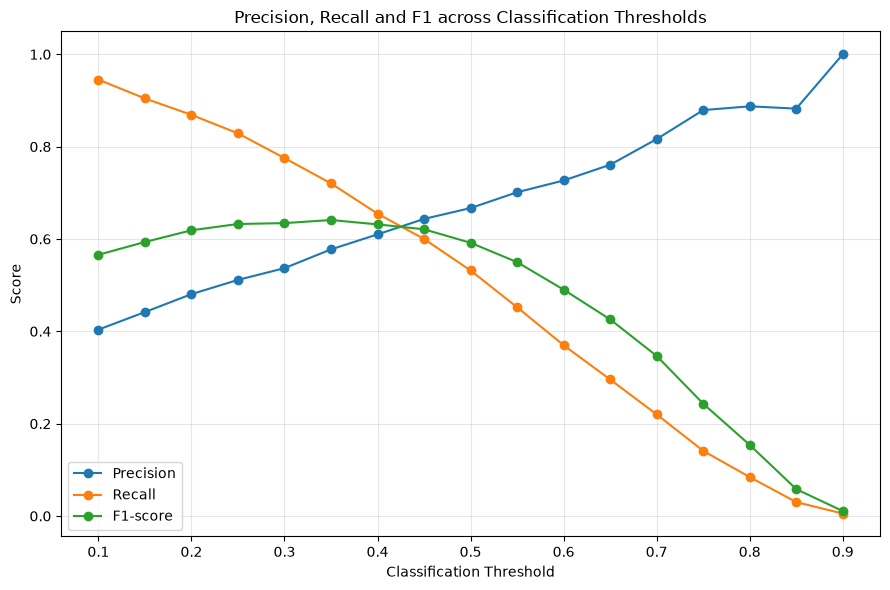

In [18]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision, Recall and F1 across Classification Thresholds"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_f1_row

threshold             0.350000
accuracy              0.785942
precision             0.577480
recall                0.720401
f1                    0.641071
false_positives     788.000000
false_negatives     418.000000
true_positives     1077.000000
true_negatives     3351.000000
Name: 5, dtype: float64

In [20]:
representative_thresholds = threshold_df[
    threshold_df["threshold"].round(2).isin(
        [0.30, 0.40, 0.50, 0.60, 0.70]
    )
]

representative_thresholds.round(4)

,threshold,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
4,0.3,0.7629,0.5368,0.7753,0.6344,1000,336,1159,3139
6,0.4,0.7973,0.6100,0.6548,0.6316,626,516,979,3513
8,0.5,0.8053,0.6669,0.5318,0.5917,397,700,795,3742
10,0.6,0.7959,0.7267,0.3699,0.4902,208,942,553,3931
12,0.7,0.7799,0.8164,0.2201,0.3467,74,1166,329,4065


In [21]:
selected_threshold = 0.35

In [22]:
selected_threshold_metrics = threshold_df.loc[
    np.isclose(
        threshold_df["threshold"],
        selected_threshold
    )
]

selected_threshold_metrics.round(4)

,threshold,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
5,0.35,0.7859,0.5775,0.7204,0.6411,788,418,1077,3351


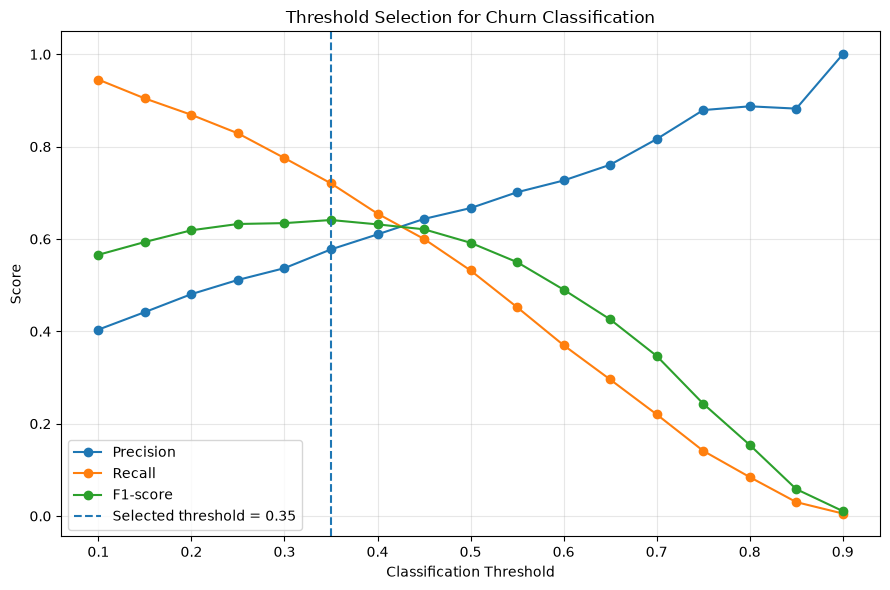

In [23]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    x=selected_threshold,
    linestyle="--",
    label=f"Selected threshold = {selected_threshold}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Selection for Churn Classification")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Selected Classification Threshold

A classification threshold of **0.35** is selected for final evaluation.

This threshold produced the highest F1-score among the evaluated operating points using out-of-fold training predictions.

At this threshold:

- recall is approximately **72%**;
- precision is approximately **58%**;
- F1-score is approximately **0.64**.

Compared with the default threshold of 0.50, the selected threshold substantially reduces false negatives and identifies more customers who eventually churn, at the cost of additional false-positive alerts.

The selected value should not be interpreted as a universally optimal business threshold. In a real deployment, the final operating point would depend on the relative financial cost of missed churners, unnecessary retention actions and available intervention capacity.

Because reliable business cost information is not available, F1-score is used as a neutral criterion for balancing precision and recall.

The threshold is fixed before final evaluation, and the held-out test set remains untouched.